In [ ]:
import torch
import matplotlib.pyplot as plt

!pip install benchmarkfcns==2.5.0
from benchmarkfcns import ackley2

In [145]:
def f(x):
  dim = x.shape[0]
  assert x.shape == (dim,1)
  X = x[0]
  Y = x[1]

  output = -200 * torch.exp(-0.2 * torch.sqrt((X**2) + (Y**2)))
  output = output.reshape(1,1)
  assert output.shape == (1,1)
  return output

# Compute the gradient
def grad_f(x):

  # Check that this is true (we set this before the for loop)
  assert x.requires_grad == True
  y = f(x)
  # Make sure output is as scalar
  assert y.shape == (1,1)
  grad_term = torch.autograd.grad(outputs=y, inputs=x, grad_outputs=torch.ones_like(y), create_graph=True)[0]

  # Save space (and get rid of any weird extra stuff)
  y = y.detach()
  x = x.detach()
  #grad_term = grad_term.detach()


  # Make sure the gradient is the same sizeas the input
  assert grad_term.shape == x.shape

  # Return
  return grad_term

In [146]:
dim = 2
# step_size = 1e-2
max_iters = int(3e4)
x0 = 2*torch.randn(dim, 1)
tol = 5e-4

In [147]:
def backward_euler_descent(f, grad_f, step_size, x0, tol=1e-3, max_iters=100, inner_iters=10):
    x_hist = []
    f_hist = []
    grad_norm_hist = []

    x = x0.clone().detach().requires_grad_(True)

    # Initial eval
    fx = f(x)
    grad_fx = grad_f(x)
    grad_norm = torch.norm(grad_fx)

    x_hist.append(x.clone().detach())
    f_hist.append(fx.item())
    grad_norm_hist.append(grad_norm.item())

    for i in range(max_iters):
        # Fixed-point iteration to solve x = x_k - α ∇f(x)
        x_new = x.clone().detach().requires_grad_(True)
        for _ in range(inner_iters):
            grad = grad_f(x_new)
            x_new = (x - step_size * grad).detach().requires_grad_(True)

        x = x_new.clone().detach().requires_grad_(True)
        fx = f(x)
        grad_fx = grad_f(x)
        grad_norm = torch.norm(grad_fx)

        x_hist.append(x.clone().detach())
        f_hist.append(fx.item())
        grad_norm_hist.append(grad_norm.item())

        print(f'i: {i}, fx: {fx.item():.3e}, grad_norm: {grad_norm.item():.3e}')

        if grad_norm <= tol:
            print('converged!')
            break

    return x, f_hist, grad_norm_hist, x_hist

In [148]:
# Set up optimization parameters (picked randomly)
dim = 2
# Played around to try to find a good step size that converages. This takes some guess work
step_size = 1e-3
max_iters = 1000
# random x
x0 = torch.randn(dim,1)
tol = 1e-1

x_opt1, f_hist1, grad_norm_hist1, x_hist1 = backward_euler_descent(f, grad_f, step_size, x0, tol=tol, max_iters=max_iters)

i: 0, fx: -1.704e+02, grad_norm: 3.408e+01
i: 1, fx: -1.716e+02, grad_norm: 3.432e+01
i: 2, fx: -1.728e+02, grad_norm: 3.456e+01
i: 3, fx: -1.740e+02, grad_norm: 3.480e+01
i: 4, fx: -1.752e+02, grad_norm: 3.504e+01
i: 5, fx: -1.765e+02, grad_norm: 3.529e+01
i: 6, fx: -1.777e+02, grad_norm: 3.554e+01
i: 7, fx: -1.790e+02, grad_norm: 3.580e+01
i: 8, fx: -1.803e+02, grad_norm: 3.606e+01
i: 9, fx: -1.816e+02, grad_norm: 3.632e+01
i: 10, fx: -1.829e+02, grad_norm: 3.659e+01
i: 11, fx: -1.843e+02, grad_norm: 3.686e+01
i: 12, fx: -1.857e+02, grad_norm: 3.713e+01
i: 13, fx: -1.871e+02, grad_norm: 3.741e+01
i: 14, fx: -1.885e+02, grad_norm: 3.769e+01
i: 15, fx: -1.899e+02, grad_norm: 3.798e+01
i: 16, fx: -1.914e+02, grad_norm: 3.827e+01
i: 17, fx: -1.929e+02, grad_norm: 3.857e+01
i: 18, fx: -1.944e+02, grad_norm: 3.887e+01
i: 19, fx: -1.959e+02, grad_norm: 3.918e+01
i: 20, fx: -1.974e+02, grad_norm: 3.949e+01
i: 21, fx: -1.990e+02, grad_norm: 3.980e+01
i: 22, fx: -1.974e+02, grad_norm: 3.949e+0

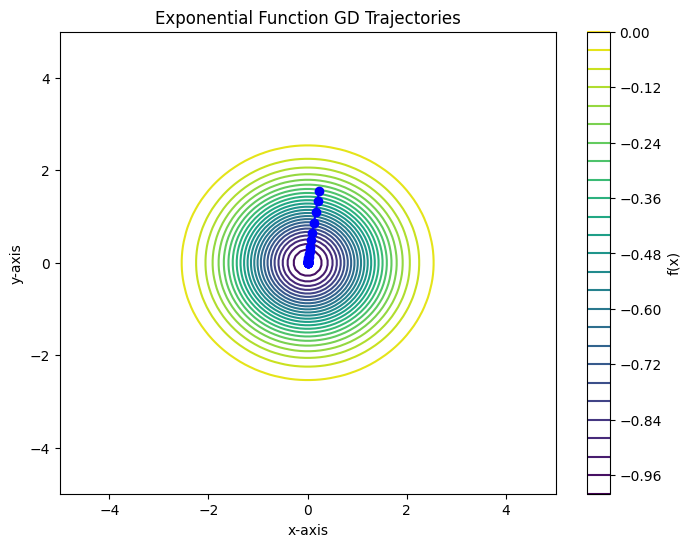

[tensor(-0.2924), tensor(-0.4013), tensor(-0.5391), tensor(-0.6831), tensor(-0.8040), tensor(-0.8880), tensor(-0.9391), tensor(-0.9679), tensor(-0.9833), tensor(-0.9914), tensor(-0.9956), tensor(-0.9978), tensor(-0.9989), tensor(-0.9994), tensor(-0.9997), tensor(-0.9998), tensor(-0.9999), tensor(-1.0000), tensor(-1.0000), tensor(-1.0000), tensor(-1.0000), tensor(-1.0000), tensor(-1.0000), tensor(-1.0000), tensor(-1.0000), tensor(-1.0000), tensor(-1.0000)]


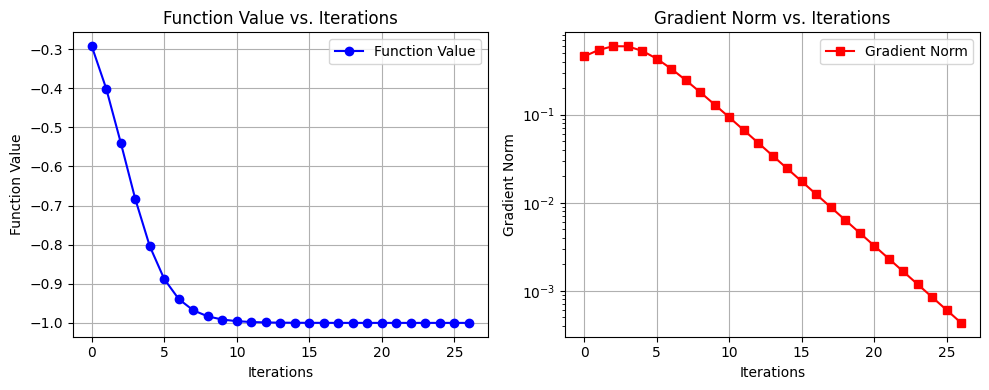

In [ ]:
xx = torch.linspace(-5,5,100)
yy = torch.linspace(-5,5,100)

# Create a 2D grid
X, Y = torch.meshgrid(xx, yy, indexing='xy') # 'xy' ensures correct indexing for 2D grid

Z_exp = torch.zeros(X.shape)
for i in range(100):
  for j in range(100):
    input_vec = torch.tensor([X[i,j], Y[i,j]]).view(2,1)
    Z_exp[i,j] = f(input_vec).item()

plt.figure(figsize=(8,6))

# plots the landscape
plt.contour(X, Y, Z_exp, levels=30, cmap='viridis')

x_coords_exp = [x[0].item() for x in x_hist1_exp] # extract x-coordinates
y_coords_exp = [x[1].item() for x in x_hist1_exp] # extract y-coordinates

# plot GD trajectory
plt.plot(x_coords_exp, y_coords_exp, marker='o', color='blue', label='GD Traj 1')

# plot minimizer
# plt.plot(x_opt1_sty, marker='x', color='red', markersize=10, markeredgewidth=5)

plt.colorbar(label='f(x)')
plt.title('Exponential Function GD Trajectories')
plt.xlabel('x-axis')
plt.ylabel('y-axis')
plt.show()

fun_vals = []
iterations = torch.arange(0,len(x_hist1_exp))
for item in x_hist1_exp:
  fun_vals.append(f(item)[0][0])

# Plot Function Value vs. Iterations
plt.figure(figsize=(10, 4))
print(fun_vals)
plt.subplot(1, 2, 1)  # Create first subplot
plt.plot(iterations, fun_vals, marker='o', linestyle='-', color='b', label="Function Value")
plt.xlabel("Iterations")
plt.ylabel("Function Value")
plt.title("Function Value vs. Iterations")
plt.grid(True)
plt.legend()


# Plot Gradient Norm vs. Iterations
plt.subplot(1, 2, 2)  # Create second subplot
plt.plot(iterations, grad_norm_hist1_exp, marker='s', linestyle='-', color='r', label="Gradient Norm")
plt.xlabel("Iterations")
plt.ylabel("Gradient Norm")
plt.yscale("log")  # Log scale to emphasize rate of decrease
plt.title("Gradient Norm vs. Iterations")
plt.grid(True)
plt.legend()

plt.tight_layout()  # Adjust layout for better appearance
plt.show()

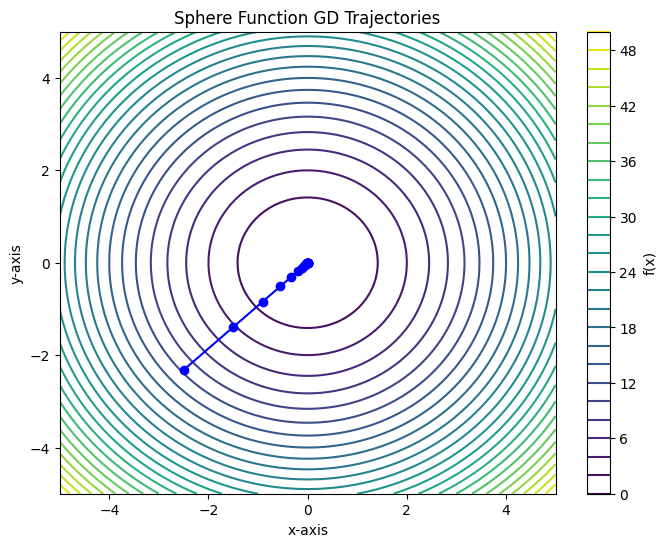

[tensor(11.6319), tensor(4.2334), tensor(1.5407), tensor(0.5607), tensor(0.2041), tensor(0.0743), tensor(0.0270), tensor(0.0098), tensor(0.0036), tensor(0.0013), tensor(0.0005), tensor(0.0002), tensor(6.2814e-05), tensor(2.2861e-05), tensor(8.3201e-06), tensor(3.0280e-06), tensor(1.1020e-06), tensor(4.0108e-07), tensor(1.4597e-07), tensor(5.3125e-08)]


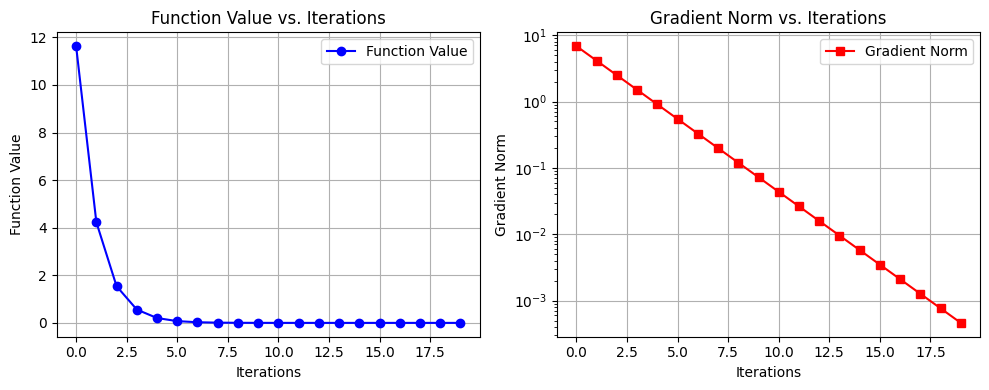

In [ ]:
xx = torch.linspace(-5,5,100)
yy = torch.linspace(-5,5,100)

# Create a 2D grid
X, Y = torch.meshgrid(xx, yy, indexing='xy') # 'xy' ensures correct indexing for 2D grid

Z_sphere = torch.zeros(X.shape)
for i in range(100):
  for j in range(100):
    input_vec = torch.tensor([X[i,j], Y[i,j]]).view(2,1)
    Z_sphere[i,j] = spheref(input_vec).item()

plt.figure(figsize=(8,6))

# plots the landscape
plt.contour(X, Y, Z_sphere, levels=30, cmap='viridis')

x_coords_sphere = [x[0].item() for x in x_hist1_sphere] # extract x-coordinates
y_coords_sphere = [x[1].item() for x in x_hist1_sphere] # extract y-coordinates

# plot GD trajectory
plt.plot(x_coords_sphere, y_coords_sphere, marker='o', color='blue', label='GD Traj 1')

# plot minimizer
# plt.plot(x_opt1_sty, marker='x', color='red', markersize=10, markeredgewidth=5)

plt.colorbar(label='f(x)')
plt.title('Sphere Function GD Trajectories')
plt.xlabel('x-axis')
plt.ylabel('y-axis')
plt.show()

fun_vals = []
iterations = torch.arange(0,len(x_hist1_sphere))
for item in x_hist1_sphere:
  fun_vals.append(spheref(item))

# Plot Function Value vs. Iterations
plt.figure(figsize=(10, 4))
print(fun_vals)
plt.subplot(1, 2, 1)  # Create first subplot
plt.plot(iterations, fun_vals, marker='o', linestyle='-', color='b', label="Function Value")
plt.xlabel("Iterations")
plt.ylabel("Function Value")
plt.title("Function Value vs. Iterations")
plt.grid(True)
plt.legend()


# Plot Gradient Norm vs. Iterations
plt.subplot(1, 2, 2)  # Create second subplot
plt.plot(iterations, grad_norm_hist1_sphere, marker='s', linestyle='-', color='r', label="Gradient Norm")
plt.xlabel("Iterations")
plt.ylabel("Gradient Norm")
plt.yscale("log")  # Log scale to emphasize rate of decrease
plt.title("Gradient Norm vs. Iterations")
plt.grid(True)
plt.legend()

plt.tight_layout()  # Adjust layout for better appearance
plt.show()

NameError: name 'x_hist1_ack' is not defined

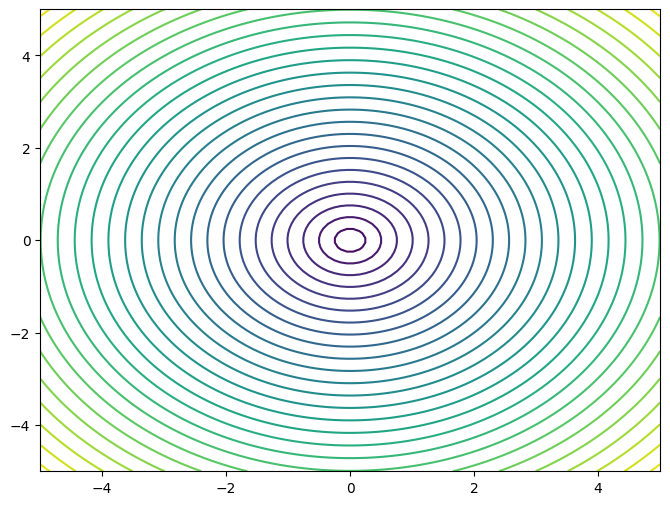

In [ ]:
xx = torch.linspace(-5,5,100)
yy = torch.linspace(-5,5,100)

# Create a 2D grid
X, Y = torch.meshgrid(xx, yy, indexing='xy') # 'xy' ensures correct indexing for 2D grid

Z_ack = torch.zeros(X.shape)
for i in range(100):
  for j in range(100):
    input_vec = torch.tensor([X[i,j], Y[i,j]]).view(2,1)
    Z_ack[i,j] = ack2(input_vec).item()

plt.figure(figsize=(8,6))

# plots the landscape
plt.contour(X, Y, Z_ack, levels=30, cmap='viridis')

x_coords_ack = [x[0].item() for x in x_hist1_ack] # extract x-coordinates
y_coords_ack = [x[1].item() for x in x_hist1_ack] # extract y-coordinates

# plot GD trajectory
plt.plot(x_coords_ack, y_coords_ack, marker='o', color='blue', label='GD Traj 1')

# plot minimizer
# plt.plot(x_opt1_sty, marker='x', color='red', markersize=10, markeredgewidth=5)

plt.colorbar(label='f(x)')
plt.title('Ackley 2 Function GD Trajectories')
plt.xlabel('x-axis')
plt.ylabel('y-axis')
plt.show()

fun_vals = []
iterations = torch.arange(0,len(x_hist1_ack))
for item in x_hist1_ack:
  fun_vals.append(ack2(item))

# Plot Function Value vs. Iterations
plt.figure(figsize=(10, 4))
print(fun_vals)
plt.subplot(1, 2, 1)  # Create first subplot
plt.plot(iterations, fun_vals, marker='o', linestyle='-', color='b', label="Function Value")
plt.xlabel("Iterations")
plt.ylabel("Function Value")
plt.title("Function Value vs. Iterations")
plt.grid(True)
plt.legend()


# Plot Gradient Norm vs. Iterations
plt.subplot(1, 2, 2)  # Create second subplot
plt.plot(iterations, grad_norm_hist1_sphere, marker='s', linestyle='-', color='r', label="Gradient Norm")
plt.xlabel("Iterations")
plt.ylabel("Gradient Norm")
plt.yscale("log")  # Log scale to emphasize rate of decrease
plt.title("Gradient Norm vs. Iterations")
plt.grid(True)
plt.legend()

plt.tight_layout()  # Adjust layout for better appearance
plt.show()